# Stage 4: fixed baseline training

Custom CNN and GRU, random initialisation. Shared seed42, weighted CE from training labels, Adam 0.001, batch32, dropout0.3, clipping1.0, max20 epochs, validation macro-F1 early stopping patience3 (significant change >0.0001). Highest observed validation F1 checkpoint is saved, earliest exact tie. Stage 2 and Stage 3 are read-only; test files are hashed for preservation but never loaded for model evaluation. No tuning is performed.

Training metrics aggregate predictions made during optimisation with masking and dropout active; validation metrics use unmasked inputs in eval mode. Weighted epoch losses use summed weighted losses divided by summed target weights. These curves are not directly comparable estimates on identically processed inputs.

The primary rubric assigns 30 marks to model building and 10 to tuning; this run is the baseline, not completed tuning or final test evaluation. See STAGE4.md for source references, results, interpretation and proposed next steps.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if not (ROOT/'src/stage4.py').exists(): ROOT=ROOT.parent
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve()
sys.path.insert(0,str(ROOT/'src'))
from stage4 import run
summary=run()
assert summary['previous_outputs_preserved'] and not summary['test_evaluated']

cnn epoch 1: masked train F1=0.4821, validation F1=0.6161, stale=0, seconds=2.25


cnn epoch 2: masked train F1=0.5880, validation F1=0.6345, stale=0, seconds=2.39


cnn epoch 3: masked train F1=0.6438, validation F1=0.6835, stale=0, seconds=2.24


cnn epoch 4: masked train F1=0.6842, validation F1=0.6974, stale=0, seconds=1.98


cnn epoch 5: masked train F1=0.7132, validation F1=0.6956, stale=1, seconds=2.38


...

gru epoch 3: masked train F1=0.7088, validation F1=0.6952, stale=0, seconds=6.34


gru epoch 4: masked train F1=0.7575, validation F1=0.7113, stale=0, seconds=5.42


gru epoch 5: masked train F1=0.8048, validation F1=0.6970, stale=1, seconds=6.04


gru epoch 6: masked train F1=0.8384, validation F1=0.6901, stale=2, seconds=6.40


gru epoch 7: masked train F1=0.8726, validation F1=0.6999, stale=3, seconds=5.11


In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(ROOT/'results/stage4/baseline_comparison.csv'))
for kind,r in summary['models'].items():
 print(kind,'best epoch',r['best_epoch'],'reload predictions/logits exact:',r['reload_predictions_exact'],r['reload_logits_exact'])
 display(pd.DataFrame(r['per_class']).T)
print('Total training and validation seconds:',summary['total_model_training_validation_seconds'])

,model,best_epoch,epochs_run,loss,accuracy,macro_f1,training_validation_seconds
0,cnn,10,13,0.744452,0.764129,0.723149,34.770488
1,gru,4,7,0.681888,0.759458,0.711305,38.790600


cnn best epoch 10 reload predictions/logits exact: True True


,precision,recall,f1-score,support
negative,0.898477,0.780882,0.835563,1360.0
neutral,0.551089,0.737668,0.630872,446.0
positive,0.676796,0.731343,0.703013,335.0


gru best epoch 4 reload predictions/logits exact: True True


,precision,recall,f1-score,support
negative,0.896321,0.788235,0.838811,1360.0
neutral,0.540630,0.730942,0.621544,446.0
positive,0.666667,0.680597,0.673560,335.0


Total training and validation seconds: 73.56108729999687


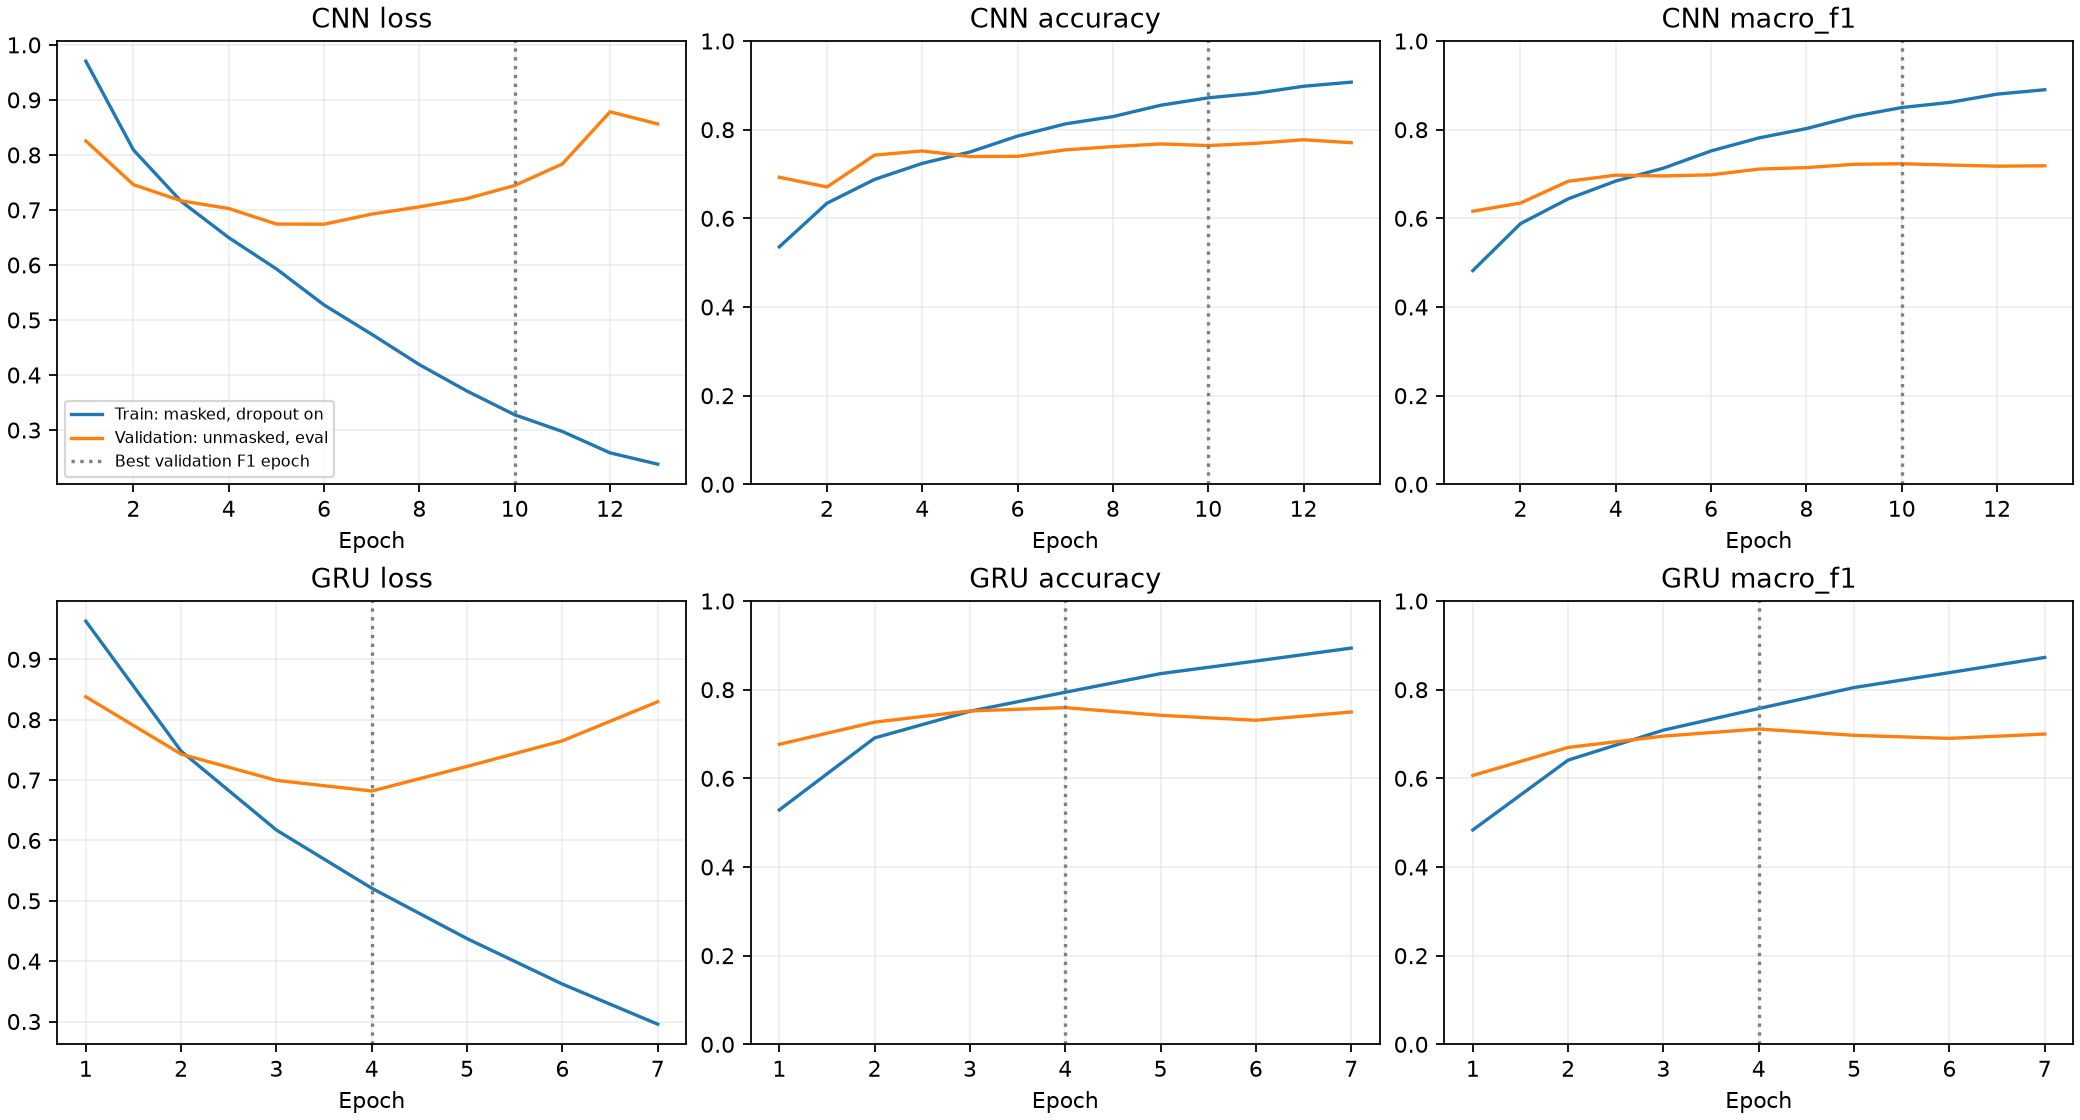

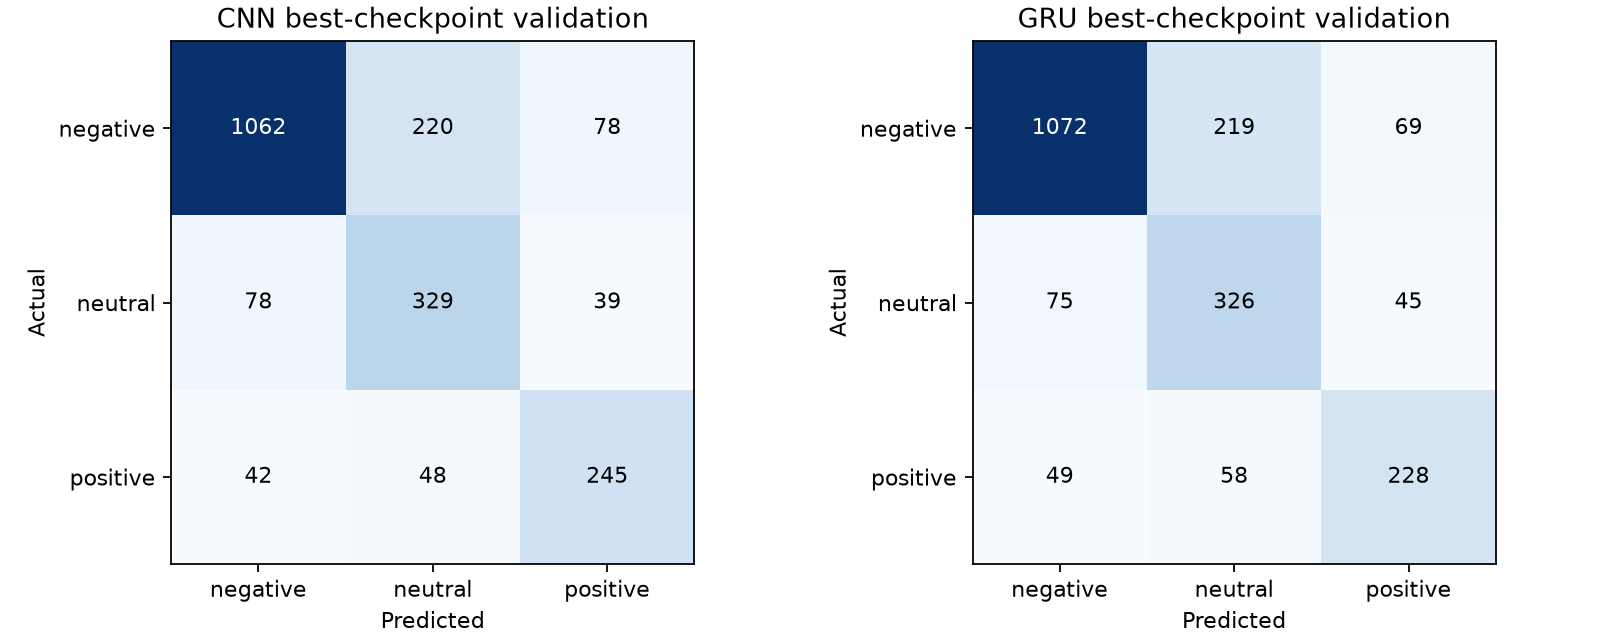

Baseline complete. Test evaluation and tuning have not started.


In [3]:
display(Image(filename=str(ROOT/'results/stage4/learning_curves.png')))
display(Image(filename=str(ROOT/'results/stage4/validation_confusion_matrices.png')))
print('Baseline complete. Test evaluation and tuning have not started.')

Checkpoints, per-epoch logs, validation predictions, class reports, raw confusion matrices, figures and hash evidence are in results/stage4/. Re-running starts fresh and archives the previous Stage 4 outputs. Validation is used for checkpoint selection, so these metrics are not an untouched final estimate. Codex generated and executed baseline training and analysis code; no assignment report or AI acknowledgement is written here.